# Assignment 7: Expectation Maximization

MIDS W281: Computer Vision

## Recommended Libraries

In [1]:
!uv pip install scikit-image

Checked 1 package in 3ms


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from skimage.color import rgb2gray
import skimage.feature
from matplotlib.patches import Circle

![Hybrid Teaser](https://raw.githubusercontent.com/W281/fileRepository/main/Assignments/output.gif)

 ### Overview
In tasks with noisy input data, it is often necessary to estimate parameters using an iterative approach. To illustrate this, we have provided you a realistic (but very simple) optimization problem. 

You are tasked with writing the software for a parts inspection system. The input to this system is a color image of a circular part. Your task is to locate and fit a circle (center and radius) to the part, and then determine whether the size of the part (its radius) is within a specified tolerance. You will use the expectation/maximization (EM) algorithm to simultaneously locate the boundary of the circular part, fit a circle to the part, and estimate the goodness of the fit.

### Description

1. To begin, your system should load a color (RGB) image, convert the image to grayscale, and extract the salient edges in the image. You can use the Canny edge detector from Python's OpenCV library to find the edges. This function will return a binary image with a value of 1 at a pixel location corresponding to a salient edge and 0 otherwise. Note that you will need to play around with the size of the filter to get a useful output. You might need to exclude the edges of the image and then extract the x- and y-coordinates of all pixels with an edge value equal to 1 (see numpy's `argwhere`). It is from these coordinates that we will find and fit a circle.  

2. The coordinates of each edge pixel correspond to one of two models:   
    (1) a circle with center $(c_x,c_y)$ and radius $(r)$; or  
    (2) an "outlier" model.  
    The conditional probability of belonging to model 1 will be modeled as a Gaussian distribution $(g(d) = exp(-d^2/σ)$ and will depend on the distance, $d$, of each point to the circle. The conditional probability of belonging to model 2 will be modeled as a uniform distribution and fixed to be 1/10.  
    **HINT: the async mentioned two kinds of conditional probabilities, figure out which kind of conditional probability was just provided for models 1 and 2, and how this kind of conditional probability is used throughout the entire EM process**

3. You should begin your EM iterations by initializing $(c_x,c_y)$ to be the image center, $r=190$ pixels, and $σ=128$.   

4. In the E-step, the residual error for model 1 is based on the shortest distance, $d$, between a point $(x,y)$ and the current estimate of the circle with center $(c_x,c_y)$ and radius, $r$. This distance is:  
    $$d=\left\lvert \sqrt{ (x-c_x)^2 + (y-c_y)^2} - r \right\rvert$$
    
5. In the M-step, you will use weighted total least-squares to re-estimate the paramters of the circle. First, implement the total least-squares estimator described in Section 2 of the gander_golub_strebel.pdf paper in the Assignment 7 GitHub repo. The weights of weighted total least-squares estimator are computed in the E-step. Incorporate this weighting into your total least-squares estimator and **solve using SVD.** 

6. After performing the E- and M-step, update the value of $σ$.  
    **HINT: when updating sigma, you can assume untied covariance and that the residuals for the noise model (model 2) is 0, but you should still be able to calculate the conditional probability that was not given above for model 2 if you understand the concepts**

7. Repeatedly perform the E- and M-steps until the difference between subsequent estimates of the circle center and radius are each less than 0.1 pixels.  

8. As shown in the sample output above, on each EM iteration you should display two images:  
    (1) the current circle superimposed on top of the original RGB image;  
    (2) the current probability of each pixel location belonging to model 1 visualized as an image. 
    
9. Show your final fitting results on the five images provided in the "discs" directory.  
**If your solution is similar to ours, it might fail on the image disc4.jpg. If so, fix this failure by choosing a better initial value for $(c_x, c_y)$.**   

### Deliverables:

- Python code to perform the above EM algorithm.  
- Plots showing the steps for for EM for each of the image.  
- Plot showing the final fitting results, i.e. the circle super-imposed on the RGB disc image.

To see a sample output of the convergence process, see images/SampleOutput.mov.  Your convegence process does not need to match it exactly, but it should be similar.

### Helper Functions

In [3]:
def load_and_transform_img(file_name: str) -> np.ndarray:
    "Read an RGB image from file and convert it to grayscale."
    rgb_img  = plt.imread(file_name)
    gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)
    return gray_img, rgb_img

In [4]:
def find_edge_coords(img: np.ndarray, **canny_kwargs) -> tuple[np.ndarray, np.ndarray]:
    "Uses the canny edge detection algorithm to predict (x,y)-coords corresponding to an edge."
    
    edge_im = skimage.feature.canny(img, **canny_kwargs)
    coords = np.argwhere(edge_im == 1)

    Y = coords[:, 0]
    X = coords[:, 1]
    return X, Y, coords

In [5]:
def compute_distances(
    X: np.ndarray, Y: np.ndarray, 
    cx: float, cy: float, r: float,
) -> np.ndarray:
    return np.abs(np.sqrt((X - cx) ** 2 + (Y-cy) ** 2) - r)

### Tuning the Canny Edge Detector

After some manual parameter sweeps and visual inspection, I found that choosing $\sigma = 2$ and using the top quartile of thresholds achieved the best Canny performance. As you can see below, we exclude significant amounts of noise while still capturing most of each disc's circumference in the sample.

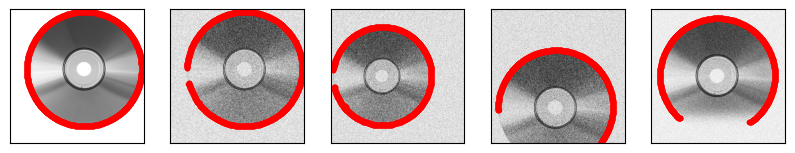

In [7]:
fig, axs = plt.subplots(1, 5, figsize=(10, 10))

for i, img_path in enumerate(os.listdir('discs')):

    img, _ = load_and_transform_img('discs/' + img_path)
    X, Y, _ = find_edge_coords(img, sigma=2, use_quantiles=True, low_threshold=0.75, high_threshold=1.0)

    axs[i].imshow(img, cmap='gray') 
    axs[i].plot(X, Y, 'r.')
    axs[i].set_xticks([])
    axs[i].set_yticks([])
    
plt.show()

### Create your Function to execute the above steps

In [8]:
def find_EM(file_name: str, **canny_kwargs) -> None:

    # Load the image and convert to grayscale
    img, rgb_img = load_and_transform_img(file_name)

    # Find edge coordinates
    X, Y, coords = find_edge_coords(img, **canny_kwargs)
    num_points = len(X)

    # Print the number of points
    print(f'Number of Points: {num_points}')

    # display the image and plot the edge coordinates
    ## display the image 
    plt.imshow(img, cmap='gray') 
    plt.plot(X, Y, 'r.')
    plt.show()

    # Expectation/Maximization
    ## intialize new center (cx, cy)/2 and radius to 190
    new_cx = img.shape[1] / 2.0 # 210
    new_cy = img.shape[0] / 2.0 # 320
    new_r  = 190

    prev_cx = 0
    prev_cy = 0
    prev_r  = 0

    ## initial sigma
    sigma = 128

    # create empty arrays for expectation and d that correspond to the number of coordinates previously calculated 
    expectation = np.zeros((num_points,))
    distances   = np.zeros((num_points,))

    # repeat optimization until the difference is less than 0.1
        ## expectation step
        ### compute the expectation of each point given prev parameters
        ### after each step, display the images with circle and expectation weights 
    
    while((np.abs(prev_cx - new_cx) > 0.1) or (np.abs(prev_cy - new_cy) > 0.1) or (np.abs(prev_r - new_r) > 0.1)):
        
        prev_cx = new_cx
        prev_cy = new_cy
        prev_r = new_r

        ## expectation step
        ### compute the expectation of each point given prev parameters
        distances   = compute_distances(X, Y, prev_cx, prev_cy, prev_r)
        expectation = np.exp((distances ** 2) / -sigma)
            
        exIm = np.zeros((img.shape[0], img.shape[1]))

        for i in range(num_points):
            r,c = np.unravel_index(coords[i], (img.shape[0], img.shape[1]))[1]
            exIm[r,c] = expectation[i]

        ## display the images with circle and expectation weights
        fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(10,5))
        ax[0].imshow(rgb_img)
        ax[0].scatter(prev_cx, prev_cy, marker='x', color='black') # Add a black 'X' at predicted center
        
        circ = Circle( (prev_cx, prev_cy), radius=prev_r, fill = False )
        ax[0].add_patch(circ)
        ax[1].imshow(exIm)
        ax[0].set_title(f'r = {np.around(prev_r, 2)}, cx = {np.around(prev_cx, 2)}, cy = {np.around(prev_cy, 2)}')
        plt.show()

        # maximization step
        # ||WBu|| minimization
        W = np.reshape(expectation / (expectation + 0.1), (-1, 1))
        
        B = np.ones((num_points, 4))
        B[:, 0] = X ** 2 + Y ** 2
        B[:, 1] = X
        B[:, 2] = Y

        # use SVD to solve for u in ||WBu||
        # use the vector with minimum eigen value
        U, S, Vh = np.linalg.svd(W * B)
        u = Vh[-1, :]
                
        # update center and radius (derived from Eqn. 2.2 in the attached paper)
        new_cx = -u[1] / (2 * u[0])
        new_cy = -u[2] / (2 * u[0])
        new_r  = np.sqrt( ((u[1]**2 + u[2]**2) / (4 * u[0]**2)) - (u[3] / u[0]) )
        
        # update sigma
        sigma = np.sum( distances ** 2 * W) / np.sum(W)

### Run your function for all disc images

Image: disc1.jpg
Number of Points: 1443


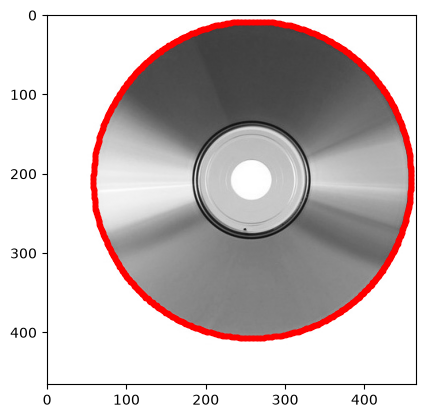

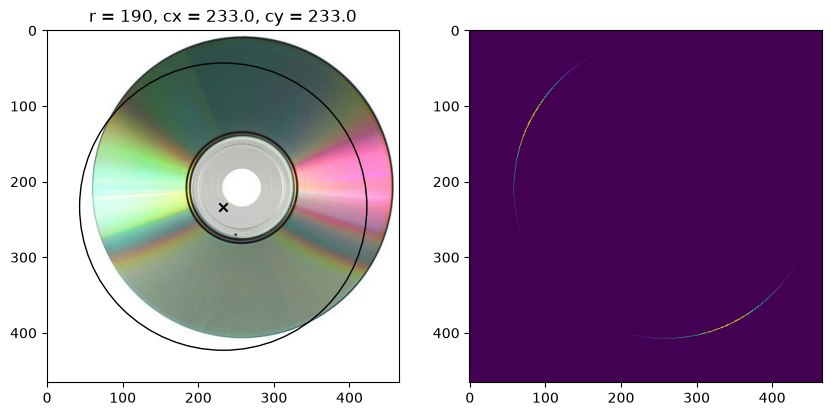

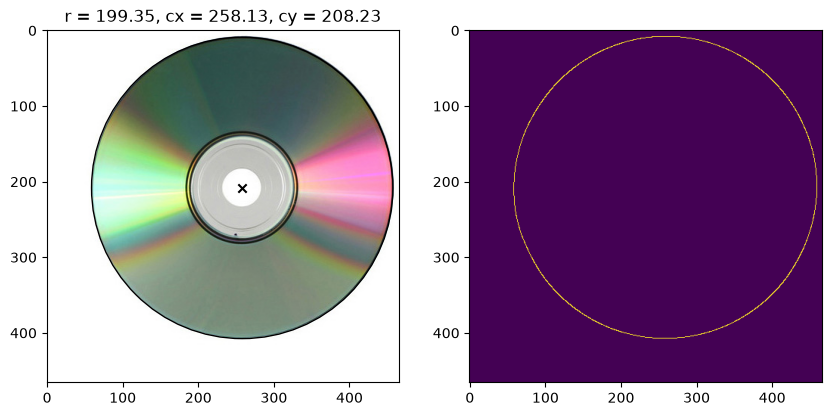

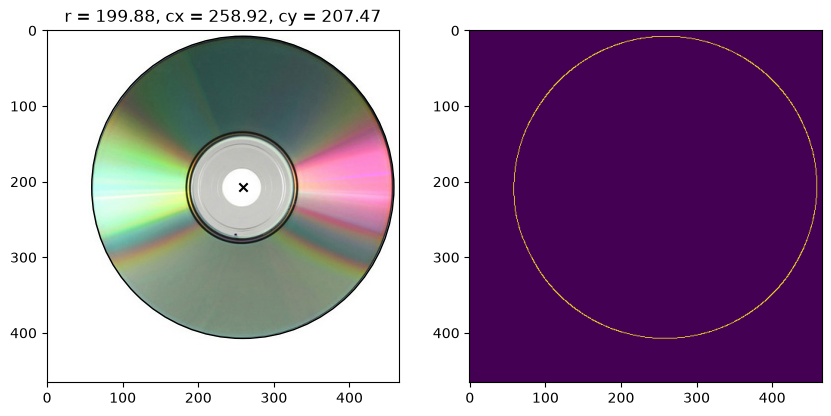

Image: disc2.jpg
Number of Points: 1394


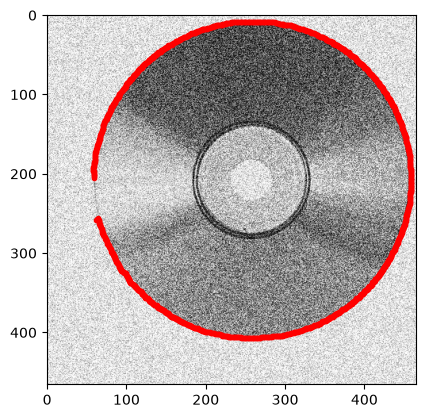

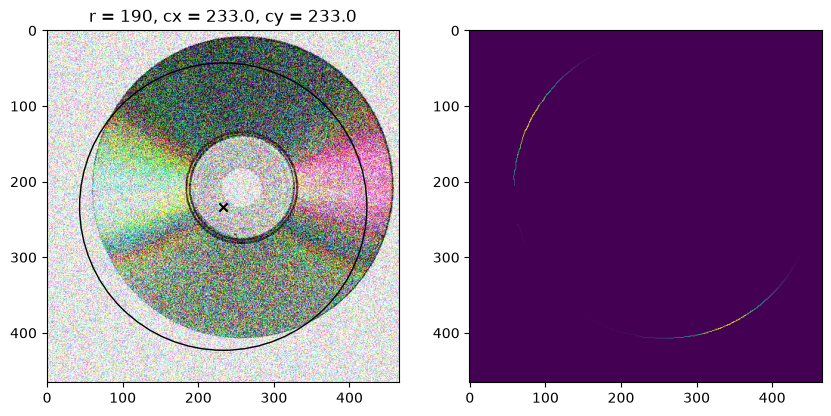

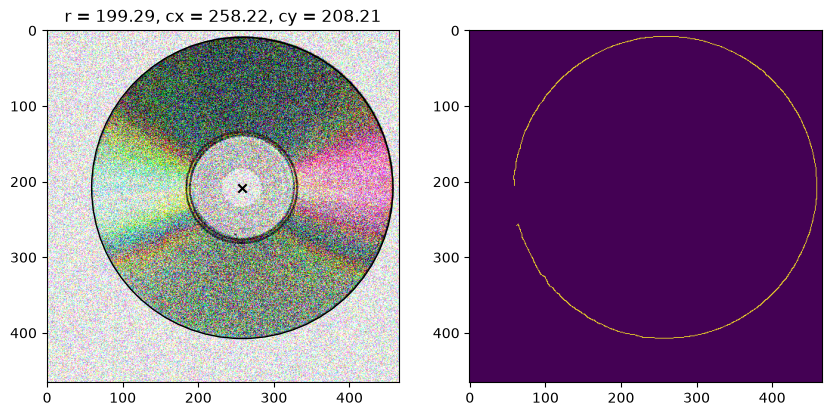

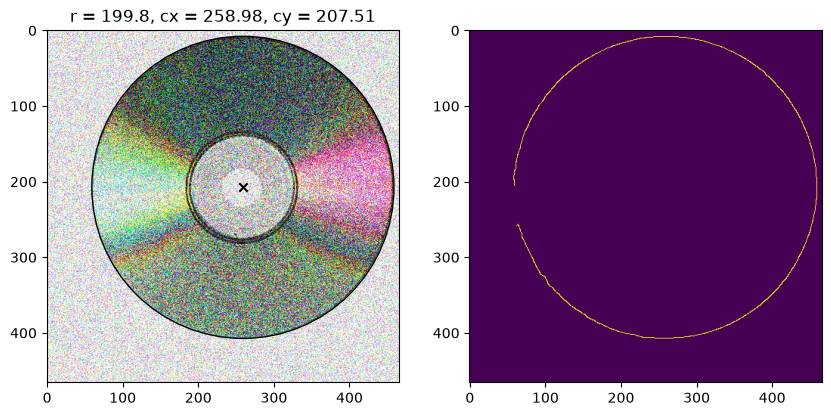

Image: disc3.jpg
Number of Points: 1194


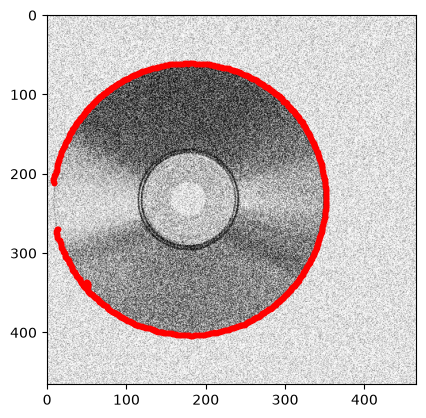

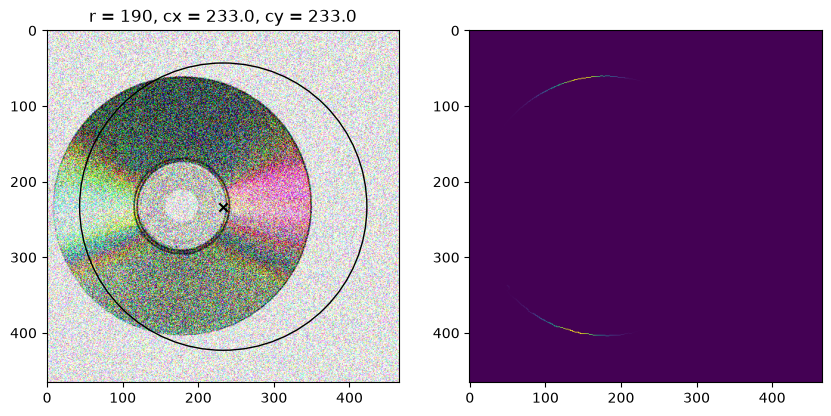

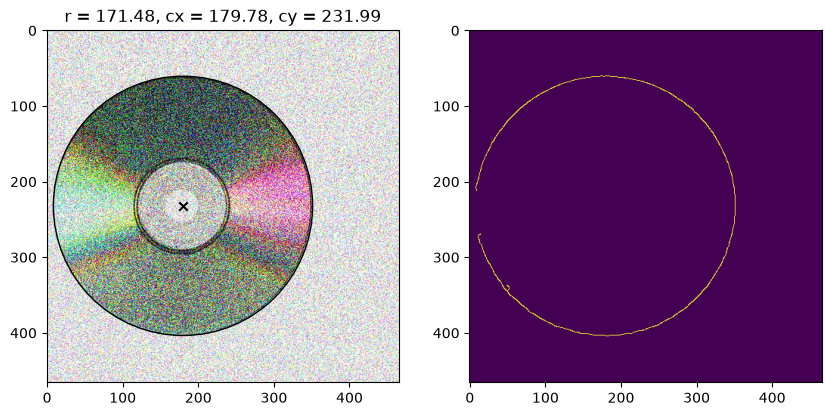

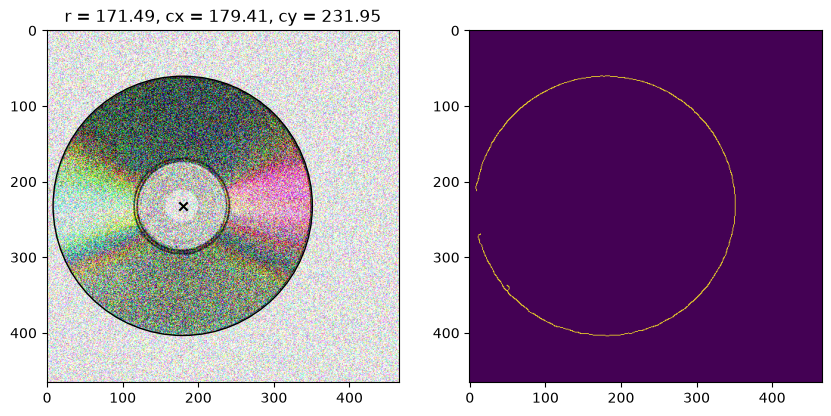

Image: disc4.jpg
Number of Points: 888


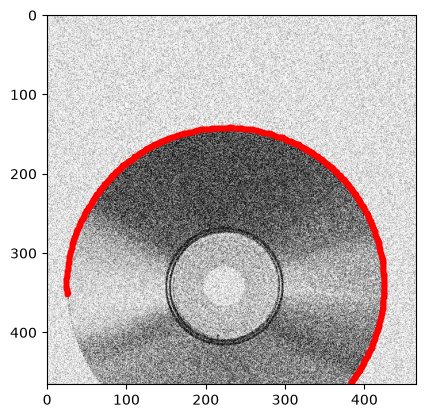

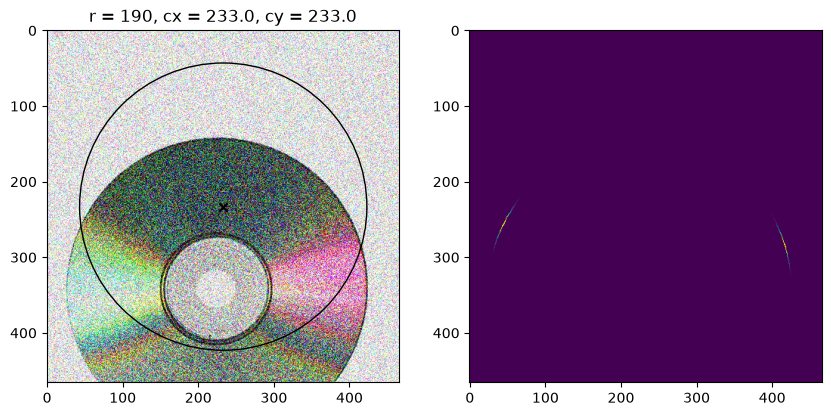

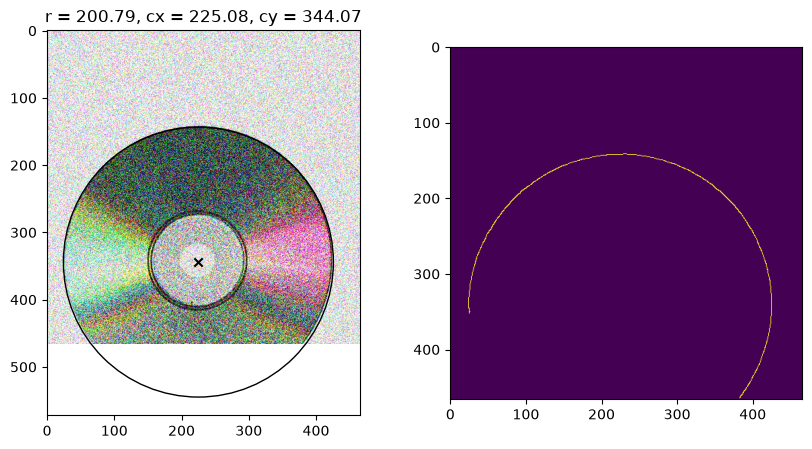

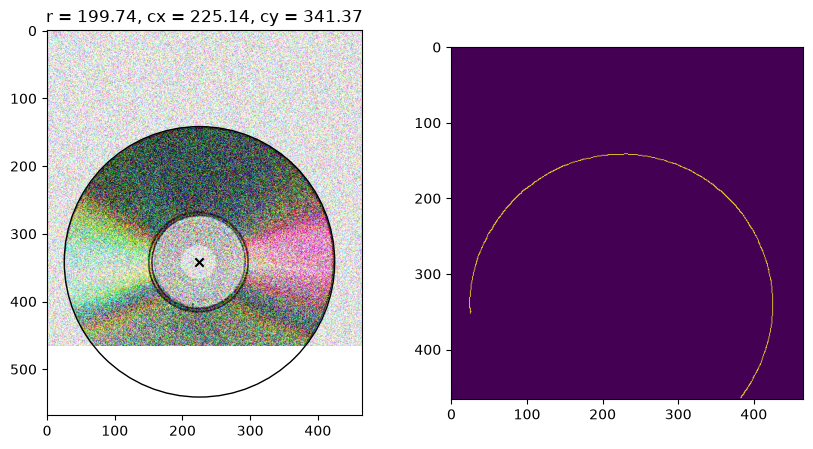

Image: disc5.jpg
Number of Points: 1153


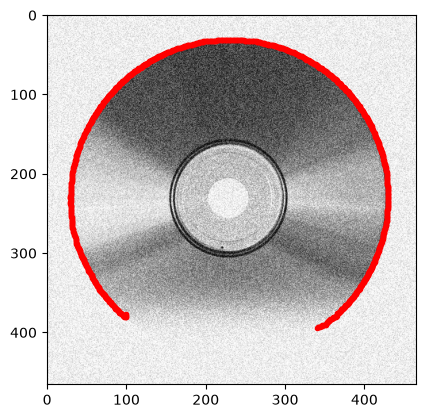

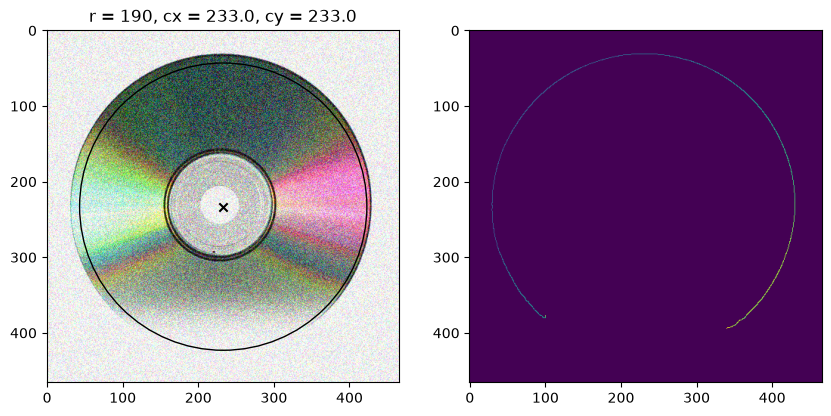

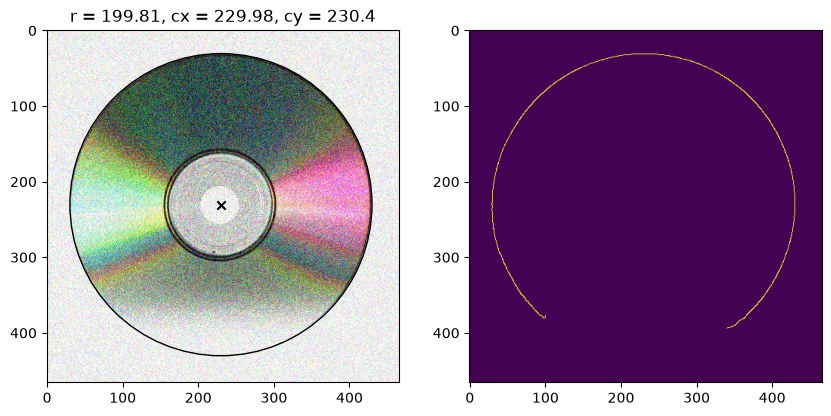

In [9]:
# Use the best Canny parameters identified earlier
CANNY_KWARGS = {
    'sigma': 2, 
    'use_quantiles': True, 
    'low_threshold': 0.75, 
    'high_threshold': 1.0,
}

# Run the full EM pipeline on all images
for image in os.listdir('discs'):
    print(f'Image: {image}')
    find_EM('discs/' + image, **CANNY_KWARGS)